# D1 · Semantic entropy and discrete SE

## Goal

**Role:** run semantic entropy (SE) and discrete SE on the shared data with probly's pipeline, validate them against the gemma experiment, and provide the reference scores for the reflexive methods.

**Pipeline:** B1's 50-question file (10 samples per question, with log likelihoods) → rebuild the probly representation (no new model run) → NLI clustering of the samples (`microsoft/deberta-base-mnli`) → SE and discrete SE per question → `results/qwen0.5b/semantic_entropy.json`, `discrete_se.json` → validation against gemma's entropy functions

**Outputs:** the two score files, the gemma validation (section 2.5), and the explanation of `uniform_logits()` (section 2.3).

## 1. Setup

In [1]:
import json
import time
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

# Make `common` importable when the notebook runs from notebooks/
ROOT = Path.cwd() if (Path.cwd() / 'common').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

from common.data import load_data

pd.set_option('display.max_colwidth', 90)
rows = load_data('qwen0.5b', 50)
df = pd.DataFrame(rows)

RES = ROOT / 'results' / 'qwen0.5b'
for method, col in [('semantic_entropy', 'se'), ('discrete_se', 'dse')]:
    scores = json.loads((RES / f'{method}.json').read_text())
    assert scores['ids'] == list(df.id), f'{method}: ids do not match the order in B1 file'
    df[col] = scores['uncertainty']
    print(f"{method}: {len(scores['ids'])} scores, failed: {sum(scores['failed'])}")
print(f'{len(df)} questions, model: {df.model[0]}, greedy accuracy {df.correct.mean():.0%}')

semantic_entropy: 50 scores, failed: 0
discrete_se: 50 scores, failed: 0
50 questions, model: Qwen/Qwen2.5-0.5B-Instruct, greedy accuracy 24%


### Settings

| Setting | Value |
|---|---|
| Model that generated the data | `Qwen/Qwen2.5-0.5B-Instruct` |
| Samples per question | 10, temperature 0.7, max 32 new tokens |
| NLI model for clustering | `microsoft/deberta-base-mnli` |
| Clusterer | probly `HFGreedySemanticClusterer` |
| Log likelihood per sample | mean token log likelihood (`samples_ll_mean`) |
| Entropy | natural log (maximum for 10 samples = ln 10 = 2.30) |
| Direction | higher = more uncertain (as in the score contract) |

**Correct or wrong?** Both scores are compared with the label `correct` of the *greedy* answer from B1's file, even though SE is computed from the 10 samples.

## 2. Implementation

### 2.1 Day 1: the probly example and its output structure

The README LLM example and `examples/llm/semantic_entropy.py` were run with SmolLM2 to see what probly returns. The structure of the objects is printed in section 2.2 right after they are built, so it is documented from real output.

### 2.2 Day 2: rebuild the representation without re-running the model

B1's file already holds the 10 samples and their log likelihoods, so the probly representation is built directly from it. First on the first 5 questions (the small test), with a check of every shape. The result must match the scores saved for the same questions.

In [ ]:
import torch
from probly.representation.text_generation.torch import (
    TorchTextGeneration, TorchTextGenerationSample)
from probly.representer.semantic_clustering.huggingface import HFGreedySemanticClusterer
# TODO: import `entropy` exactly as in probly's examples/llm/semantic_entropy.py

def build_sample(subset):
    samples = [r['samples'] for r in subset]                        # n lists of 10 texts
    samples_ll_mean = [r['samples_ll_mean'] for r in subset]        # n lists of 10 floats
    gen = TorchTextGeneration(text=np.array(samples, dtype=object),
                              log_likelihood=torch.tensor(samples_ll_mean))
    return TorchTextGenerationSample(tensor=gen, sample_dim=1)

clusterer = HFGreedySemanticClusterer.from_model_name('microsoft/deberta-base-mnli')

small = rows[:5]
sample = build_sample(small)
assert sample.tensor.text.shape == (5, 10)
assert tuple(sample.tensor.log_likelihood.shape) == (5, 10)

semantic = clusterer(sample)
se_small = entropy(semantic.to_dense())
dse_small = entropy(semantic.uniform_logits().to_dense())
assert tuple(se_small.shape) == tuple(dse_small.shape) == (5,)

print('text', sample.tensor.text.shape, '| log_likelihood', tuple(sample.tensor.log_likelihood.shape))
print('semantic:', type(semantic).__name__, '| to_dense:', tuple(semantic.to_dense().shape))
print('SE  rebuilt vs saved:', np.allclose(np.asarray(se_small), df.se[:5], atol=1e-4))
print('DSE rebuilt vs saved:', np.allclose(np.asarray(dse_small), df.dse[:5], atol=1e-4))

**Output structure.** `text` is `(n, 10)` and `log_likelihood` is `(n, 10)`; `semantic` holds the cluster assignment of every sample, and `to_dense()` turns it into one distribution over clusters per question; both entropies are one number per question, shape `(n,)`.

**If the rebuild fails:** run the sampler once with the model and feed its output straight into the clusterer, then note the problem as a tutor question:

```python
sampler = HFTextGenerationSampler(model, tok, num_samples=10, temperature=0.7, max_new_tokens=32)
semantic = clusterer(sampler(prompts))
```

### 2.3 What `uniform_logits()` does

`semantic.to_dense()` gives each cluster the combined likelihood of its samples, so a likely answer counts more: this is **SE**. `semantic.uniform_logits().to_dense()` first sets all sample likelihoods to the same value, so a cluster's weight is just *its share of the 10 samples*: this is **discrete SE**. The method already existed in probly's `torch_sparse_log_categorical.py`, but nothing used it.

This gives a check that needs no model: if `uniform_logits()` does what it should, every discrete SE value must equal the entropy of some split of 10 samples into clusters (for example 8/1/1 or 5/3/2).

In [2]:
def partitions(n, largest=None):
    largest = largest or n
    if n == 0:
        yield ()
        return
    for k in range(min(n, largest), 0, -1):
        for rest in partitions(n - k, k):
            yield (k,) + rest

def share_entropy(sizes):
    p = np.array(sizes) / sum(sizes)
    return float(-(p * np.log(p)).sum())

splits = {p: share_entropy(p) for p in partitions(10)}
matches = [[p for p, h in splits.items() if abs(h - v) < 1e-5] for v in df.dse]

print(f'{sum(len(m) >= 1 for m in matches)}/{len(df)} discrete SE values equal the entropy of a split of the 10 samples')
print(f'{sum(len(m) > 1 for m in matches)} of them fit more than one split')
pick = [0, 1, 2, 10, 19]
pd.DataFrame({'id': pick,
              'discrete SE': df.dse[pick].round(3).to_numpy(),
              'cluster sizes': [' or '.join(map(str, matches[i])) for i in pick]})

50/50 discrete SE values equal the entropy of a split of the 10 samples
3 of them fit more than one split


   id  discrete SE                          cluster sizes
0   0        0.639                              (8, 1, 1)
1   1        2.164            (2, 1, 1, 1, 1, 1, 1, 1, 1)
2   2        1.314                           (3, 3, 3, 1)
3  10        0.000                                  (10,)
4  19        1.609  (4, 2, 1, 1, 1, 1) or (2, 2, 2, 2, 2)

All 50 discrete SE values are the entropy of a plain count split, so the uniform weighting works as intended. Example: id 0 has 7 times *United Kingdom*, *UK*, *Australia* and one long sentence. Its discrete SE of 0.639 is exactly the entropy of an 8/1/1 split, so the clusterer put *UK* together with *United Kingdom*, which is what we want from semantic clustering.

This check does not replace the validation against gemma (section 2.5): it shows the weighting is uniform, not that the clusters agree with another implementation.

### 2.4 Day 3: all 50 questions, saved per the score contract

Same steps as in 2.2 on all 50 questions, with timing, written in the contract format (higher = more uncertain, no missing values, ids in B1's order). The files in `results/qwen0.5b/` were produced this way; the cell checks the new run against them before writing.

In [ ]:
sample = build_sample(rows)

t0 = time.perf_counter()
semantic = clusterer(sample)
se_all = np.asarray(entropy(semantic.to_dense()))
dse_all = np.asarray(entropy(semantic.uniform_logits().to_dense()))
seconds = time.perf_counter() - t0

assert se_all.shape == dse_all.shape == (len(rows),)
assert not (np.isnan(se_all).any() or np.isnan(dse_all).any())
print('matches the saved scores:', np.allclose(se_all, df.se, atol=1e-4), np.allclose(dse_all, df.dse, atol=1e-4))

def save_contract(method, values):
    out = {'method': method, 'model': df.model[0],
           'answer': 'samples',   # computed from the 10 samples, not from the greedy answer
           'ids': [int(i) for i in df.id], 'uncertainty': [float(v) for v in values],
           'failed': [False] * len(df), 'seconds_per_question': seconds / len(df)}
    (RES / f'{method}.json').write_text(json.dumps(out, indent=1))

save_contract('semantic_entropy', se_all)
save_contract('discrete_se', dse_all)
print(f'saved; {seconds / len(df):.3f} s per question (clustering + entropy, no generation)')

### 2.5 Day 3: validation against the gemma experiment

probly's cluster assignments (`group_ids`) are passed to gemma's independent implementation. On the same clusters the entropies must be almost identical: `cluster_assignment_entropy` against discrete SE, `weighted_semantic_entropy` against SE.

In [ ]:
# gemma experiment: experiments/gemma/src/gemma_experiment/semantic_entropy.py
# TODO: adapt the import path and the call arguments to the real function signatures
from gemma_experiment.semantic_entropy import cluster_assignment_entropy, weighted_semantic_entropy

group_ids = np.asarray(semantic.group_ids)                    # TODO: check the attribute name in probly
ll = sample.tensor.log_likelihood.numpy()

gemma_dse = np.array([cluster_assignment_entropy(g) for g in group_ids])
gemma_se = np.array([weighted_semantic_entropy(g, l) for g, l in zip(group_ids, ll)])

validation = pd.DataFrame({
    'comparison': ['discrete SE vs cluster_assignment_entropy', 'SE vs weighted_semantic_entropy'],
    'max abs difference': [np.abs(dse_all - gemma_dse).max(), np.abs(se_all - gemma_se).max()],
    'mean abs difference': [np.abs(dse_all - gemma_dse).mean(), np.abs(se_all - gemma_se).mean()],
})
print(f'{len(df)} questions, same clusters')
validation

**Result:** *fill in from the cell above: largest difference for each pair.* The two implementations agree if the largest difference is around 1e-4 or smaller (float precision). A larger gap on single questions means a difference in how the likelihoods are normalised, and goes to the tutors.

## 3. Results

### 3.1 The scores

In [3]:
wrong = ~df.correct
def describe(s):
    return {
        'mean, correct answers': round(s[~wrong].mean(), 2),
        'mean, wrong answers': round(s[wrong].mean(), 2),
        'questions with score 0': int((s == 0).sum()),
        'distinct values': s.round(6).nunique(),
        'max': round(s.max(), 2),
    }
pd.DataFrame({'SE': describe(df.se), 'discrete SE': describe(df.dse)}, dtype=object)

                          SE discrete SE
mean, correct answers   0.54        0.59
mean, wrong answers     1.36        1.42
questions with score 0   6.0         6.0
distinct values         45.0        24.0
max                     2.16        2.16

In [4]:
rho = spearmanr(df.se, df.dse).statistic
print(f'Spearman correlation SE vs discrete SE: {rho:.3f}')
print(f'discrete SE >= SE on {(df.dse >= df.se - 1e-9).sum()}/{len(df)} questions')
i = (df.se - df.dse).abs().idxmax()
print(f'largest difference: id {df.id[i]}, SE {df.se[i]:.2f} vs discrete SE {df.dse[i]:.2f}')
print('score 0 for both:', list(df.id[(df.se == 0) & (df.dse == 0)]),
      '| of these correct:', int(df.correct[(df.se == 0) & (df.dse == 0)].sum()))

Spearman correlation SE vs discrete SE: 0.992
discrete SE >= SE on 43/50 questions
largest difference: id 49, SE 1.63 vs discrete SE 1.97
score 0 for both: [10, 11, 30, 38, 40, 48] | of these correct: 4


Wrong answers have clearly higher entropy than correct ones on average (about 1.4 vs 0.5–0.6 for both scores). SE and discrete SE are almost the same score: the rank correlation is 0.99 and they are identical wherever all 10 samples fall into one cluster. Discrete SE is a little higher on most questions and takes only 24 different values (SE: 45), so it has many ties, which matters for AURC. No question reached the maximum of 10 different clusters (the highest value, 2.16, is nine clusters: one pair and eight single answers). Six questions have score 0 (all samples in one cluster): four are correct, two are wrong.

### 3.2 Example questions

In [5]:
def show(qid):
    r = df.loc[df.id == qid].iloc[0]
    print(f'[{qid}] {r.question[:110]}')
    print(f'  greedy : {r.greedy_answer[:90]!r}  (correct={r.correct})')
    print(f'  answer : {r.aliases[0]}')
    print(f'  SE {r.se:.2f}   discrete SE {r.dse:.2f}')
    print(f'  samples: {[s[:45] for s in r.samples]}')
    print()

show(48)  # all samples identical: score 0, correct
show(10)  # score 0 but wrong
show(17)  # correct but high entropy: long free-text answers
show(49)  # wrong, samples scatter over many names

[48] In which year was Sputnik, the first man-made satellite, launched?
  greedy : '1957'  (correct=True)
  answer : 1957
  SE 0.00   discrete SE 0.00
  samples: ['1957', '1957', '1957', '1957', '1957', '1957', '1957', '1957', '1957', '1957']

[10] The word Tet in the Tet Offensive (N Vietnam/Viet Cong against S Vietnam/US forces on 30 Jan 1968) referred to
  greedy : 'Vietnam'  (correct=False)
  answer : New Year
  SE 0.00   discrete SE 0.00
  samples: ['Nationality of Vietnam', 'Tet Offensive refers to the Vietnamese Nation', 'Vietnam', 'Vietnam', 'Vietnam', 'Vietnam', 'National Liberation Army', 'Vietnam', 'Vietnam', 'Vietnam']

[17] What would you expect if you asked for Focaccia in an Italian restaurant?
  greedy : 'Focaccia is likely to be served fresh and warm, possibly with olive oil, garlic, and herbs'  (correct=True)
  answer : Bread
  SE 1.47   discrete SE 1.47
  samples: ['Focaccia is a typical Italian dish made from ', 'Focaccia is a traditional Italian bread, not ', 'Foca

- **Id 48 (Sputnik):** ten identical answers, score 0, correct. The case the methods are built for.
- **Id 10 (Tet Offensive):** score 0 but the answer is wrong. The samples are mostly *Vietnam*, but a few read differently (*Nationality of Vietnam*, *National Liberation Army*) and still end up in one cluster, so the clusterer may be lenient here. Id 38 (*What does a querulous person do?*) is similar: ten different sentences that all start with *A querulous person ...* get score 0. The `group_ids` from section 2.5 let us look at these two directly.
- **Id 17 (Focaccia):** the greedy answer is correct, but the samples are ten differently worded sentences, so entropy is high. Long answers can inflate SE even when the content agrees.
- **Id 49:** the samples scatter over many different names (*John Wayne Gacy* appears three times), which gives a high score. Discrete SE (1.97) is higher than SE (1.63) here, the largest difference between the two.

### 3.3 Do the scores relate to correctness?

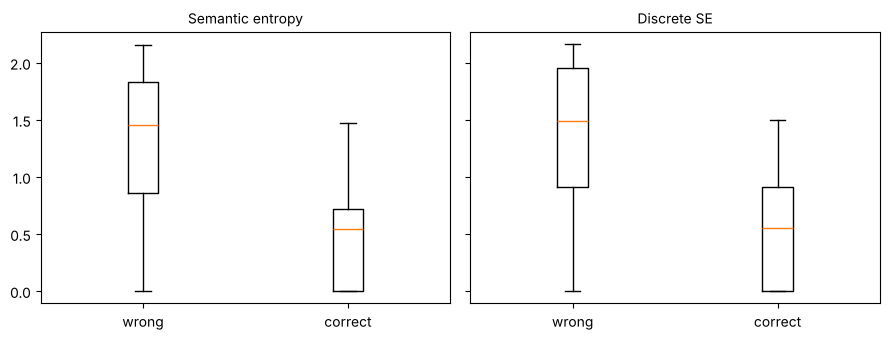

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
for ax, col, title in [(axes[0], 'se', 'Semantic entropy'), (axes[1], 'dse', 'Discrete SE')]:
    ax.boxplot([df.loc[wrong, col], df.loc[~wrong, col]], tick_labels=['wrong', 'correct'])
    ax.set_title(title, fontsize=10)
fig.tight_layout()
plt.show()

In [7]:
def auroc_ci(u, n_boot=1000, seed=0):
    # wrong answer = positive class, higher score = more uncertain
    u, y = np.asarray(u, float), wrong.to_numpy()
    rng = np.random.default_rng(seed)
    aucs = []
    for _ in range(n_boot):
        i = rng.integers(0, len(u), len(u))
        if y[i].all() or (~y[i]).all():
            continue
        aucs.append(roc_auc_score(y[i], u[i]))
    lo, hi = np.percentile(aucs, [2.5, 97.5])
    return roc_auc_score(y, u), lo, hi

# likelihood_mean = baseline from scripts/baseline_likelihood.py: -(mean token log likelihood of the greedy answer)
candidates = {'likelihood_mean': -df.greedy_ll_mean, 'semantic_entropy': df.se, 'discrete_se': df.dse}
res = pd.DataFrame([(m, *auroc_ci(u)) for m, u in candidates.items()],
                   columns=['method', 'auroc', 'ci_low', 'ci_high'])
res['CI above 0.5'] = res.ci_low > 0.5
res.round(3)

             method  auroc  ci_low  ci_high  CI above 0.5
0   likelihood_mean  0.814   0.656    0.943          True
1  semantic_entropy  0.838   0.716    0.944          True
2       discrete_se  0.839   0.718    0.948          True

Both entropy scores reach an AUROC of about 0.84, slightly above the free likelihood baseline (0.81), and the interval stays above 0.5. The three intervals overlap almost completely, so with only 12 correct answers we cannot say that SE beats the baseline, or that SE beats discrete SE (0.838 vs 0.839).

For the full comparison with AURC (ties broken randomly) and all other methods, B2's `summary_table()`:

In [ ]:
from common.summary import summary_table

table = summary_table(rows)
table = table[~table.method.str.endswith('_details')]  # extra per-question files, not score files
table['CI above 0.5'] = table.ci_low > 0.5
table.sort_values('auroc', ascending=False).round(3).reset_index(drop=True)

## 4. Issues from the plan

**Rebuilding the representation fails.** Section 2.2 builds the representation from B1's file and checks every shape and the match with the saved scores. If it fails, the fallback is to run the sampler once and use its output directly (code in 2.2), and to note the problem as a tutor question.

**Discrete and weighted SE are almost identical.** They are here: rank correlation 0.99, AUROC 0.838 vs 0.839, and identical wherever all samples fall into one cluster. That is the expected outcome, since the Nature paper found similar performance for the two. The likelihood weighting adds nothing on this data.

## 5. What works / what does not

**Works**
- SE and discrete SE for all 50 questions, no failed scores, ids in the same order as B1's file
- Both reach AUROC ≈ 0.84 against the correctness of the greedy answer, a bit above the likelihood baseline (0.81)
- Mean entropy of wrong answers is about 2.5 times that of correct ones
- Every discrete SE value is the entropy of a plain count split, so `uniform_logits()` weights the samples uniformly
- Discrete SE needs no likelihoods and gives the same ranking as SE

**Does not work (yet)**
- SE and discrete SE are almost the same score here, so the weighting by likelihood adds nothing on this data
- Some questions get score 0 although the answer is wrong (ids 10 and 38); the clusters may be too lenient
- Long free-text answers (e.g. id 17) split into many clusters and inflate entropy
- Only 12 correct answers: the AUROC intervals are wide, so differences between methods are not meaningful yet
- Discrete SE has many ties (24 distinct values), so AURC depends on how ties are broken
- The agreement with gemma (section 2.5) is not filled in until that cell has been run

## 6. Questions for the tutors
1. Should discrete SE be a clusterer parameter or a separate measure?
2. SE and discrete SE rank the questions almost the same. Is discrete SE, which needs no likelihoods, enough as the default?
3. The samples come from Qwen's default `top_p=0.8` / `top_k=20` sampling. Does this make the samples too similar and push SE down?

## 7. Where we are

- ☑ SE and discrete SE on 50 questions in `results/qwen0.5b/` (`semantic_entropy.json`, `discrete_se.json`)
- ☐ Send both files to R1–R3 (Day 3)
- ☐ Entropy agreement with gemma on the same clusters: run section 2.5 and fill in the result
- ☑ Use of `uniform_logits()` explained (section 2.3)

## 8. Talk for the meeting (2–3 minutes)

> "Discrete SE was almost ready in probly: `uniform_logits()` existed but was unused. We ran it on the shared data, 50 TriviaQA questions answered by Qwen2.5-0.5B with 10 samples each, and validated it against the gemma experiment's independent implementation: on the same clusters the entropies differ by at most **[fill in from 2.5]**.
>
> Both scores separate correct from wrong answers: the average entropy is about 0.5 for correct answers and about 1.4 for wrong ones, and the AUROC is 0.84 for both SE and discrete SE, against 0.81 for the free likelihood baseline. With only 12 correct answers the intervals overlap, so we do not claim that either beats the baseline.
>
> SE and discrete SE are almost the same score: rank correlation 0.99. The likelihood weighting adds nothing here, which fits what the Nature paper found. Discrete SE has the advantage that it needs no likelihoods, so it also works for models that do not expose them.
>
> Two things to watch: a few questions get entropy 0 although the answer is wrong, so the clusters may be too lenient, and long answers split into many clusters and inflate entropy.
>
> Our question: should discrete SE be a parameter of the clusterer, or a separate measure?"